#### EDA Student Performance Indicator

#### 1) Problem statement
- This project understands how the student's performance (test scores) is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch and Test preparation course.


#### 2) Data Collection
- Dataset Source - https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetId=74977
- The data consists of 8 column and 1000 rows.

#### 3) Dataset Information
- gender : sex of students  -> (Male/female)
- race/ethnicity : ethnicity of students -> (Group A, B,C, D,E)
- parental level of education : parents' final education ->(bachelor's degree,some college,master's degree,associate's degree,high school)
- lunch : having lunch before test (standard or free/reduced)
- test preparation course : complete or not complete before test
- math score
- reading score
- writing score

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore') 

In [2]:
df = pd.read_csv("D:\\EDA\\stud.csv")
df.head() 

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
df.shape 

(1000, 8)

### 3. Data Checks to perform
- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

In [4]:
# check missing values
df.isnull().sum() 

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

#### Insights or Observation
There are no missing values

In [ ]:
df.isna().sum() #isna() is used to find missing/null values in a DataFrame or Series.

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [6]:
# check duplicated
df.duplicated().sum() 

np.int64(0)

In [ ]:
# check datatypes
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [8]:
# checking the number of uniques values of each columns
df.nunique() 

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

In [9]:
# stastics of the dataset
df.describe() 

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


##### Insights or Observation
- From the above description of numerical data,all means are very close to each other- between 66 and 69
- All the standard deviation are also close- between 14.6- 15.19
- While there is a minimum of 0 for maths,other are having 17 and 10 value

In [10]:
# explore more info about data
df.head() 

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [40]:
[feature for feature in df.columns if df[feature].dtype!='str']    

['math_score', 'reading_score', 'writing_score']

In [38]:
# segrregate numerical and categorical features
numerical_features = [feature for feature in df.columns if df[feature].dtype!='str'] 
categorical_features = [feature for feature in df.columns if df[feature].dtype=='str'] 

In [36]:
numerical_features

['math_score', 'reading_score', 'writing_score']

In [39]:
categorical_features

['gender',
 'race_ethnicity',
 'parental_level_of_education',
 'lunch',
 'test_preparation_course']

In [41]:
df.head() 

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [42]:
# Aggregate the total score with mean
df['total_score'] = (df['math_score']+df['reading_score']+df['writing_score'])
df['average'] = df['total_score']/3
df.head() 

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


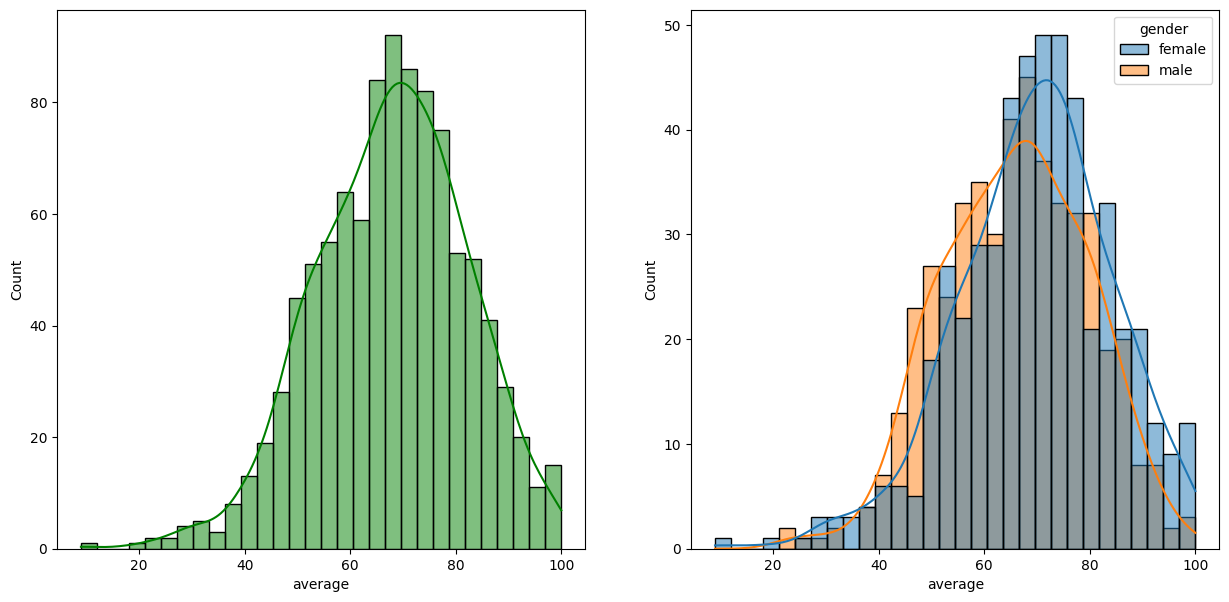

In [ ]:
# Explore more visulaizatio
fig,axis = plt.subplots(1,2,figsize=(15,7))
plt.subplot(121) # 1 row, 2 columns, chart 1
sns.histplot(data = df,x='average',bins = 30,kde = True,color = 'g')
plt.subplot(122)
sns.histplot(data=df,x='average',bins=30,kde = True,hue='gender')
plt.show() 

#### Insights
- Female student tend to perform well than male students

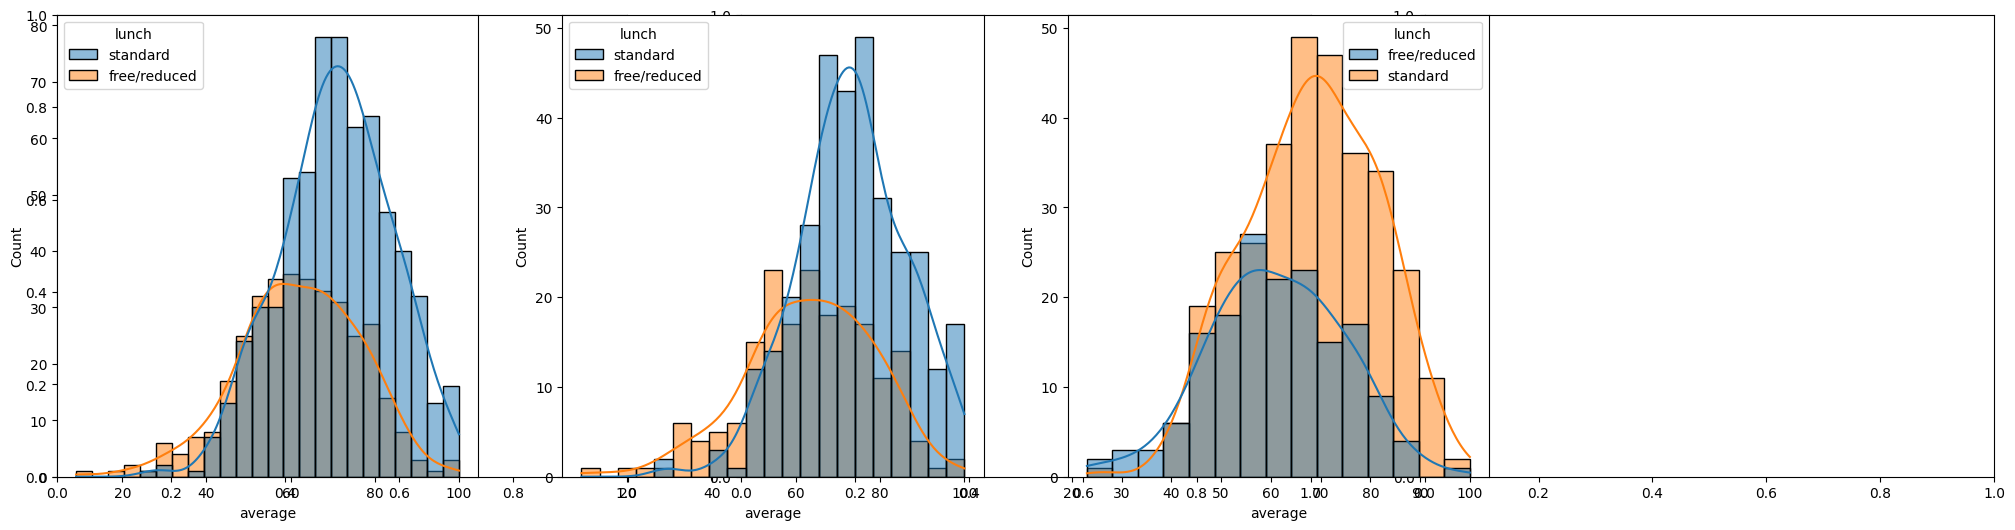

In [ ]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131) # 1 row, 3 columns, chart 1
sns.histplot(data=df,x='average',kde=True,hue='lunch')
plt.subplot(132) # chart 2
sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='lunch')
plt.subplot(133) # chart 3
sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='lunch')
plt.show() 

### Insights
- Standard Lunch help students perform well in exams
- Standard lunch helps perform well in exams be it a male of female

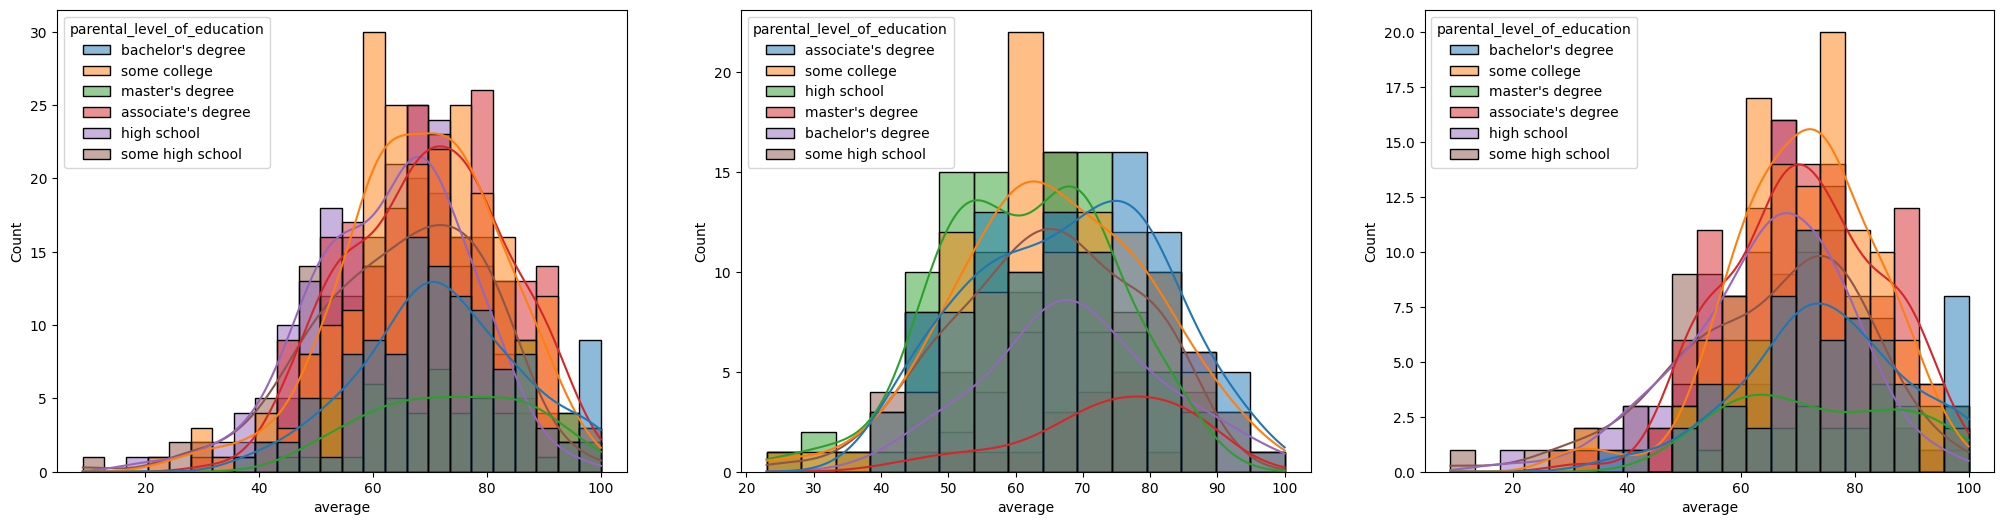

In [64]:
plt.subplots(1,3,figsize=(25,6))
plt.subplot(131) # 1 row, 3 columns, chart 1
ax = sns.histplot(data=df,x='average',kde=True,hue='parental_level_of_education')
plt.subplot(132)
ax=sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='parental_level_of_education')
plt.subplot(133)
ax=sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='parental_level_of_education')
plt.show() 

#####  Insights
- In general parent's education don't help student perform well in exam.
- 2nd plot shows that parent's whose education is of associate's degree or master's degree their male child tend to perform well in exam
- 3rd plot we can see there is no effect of parent's education on female students.

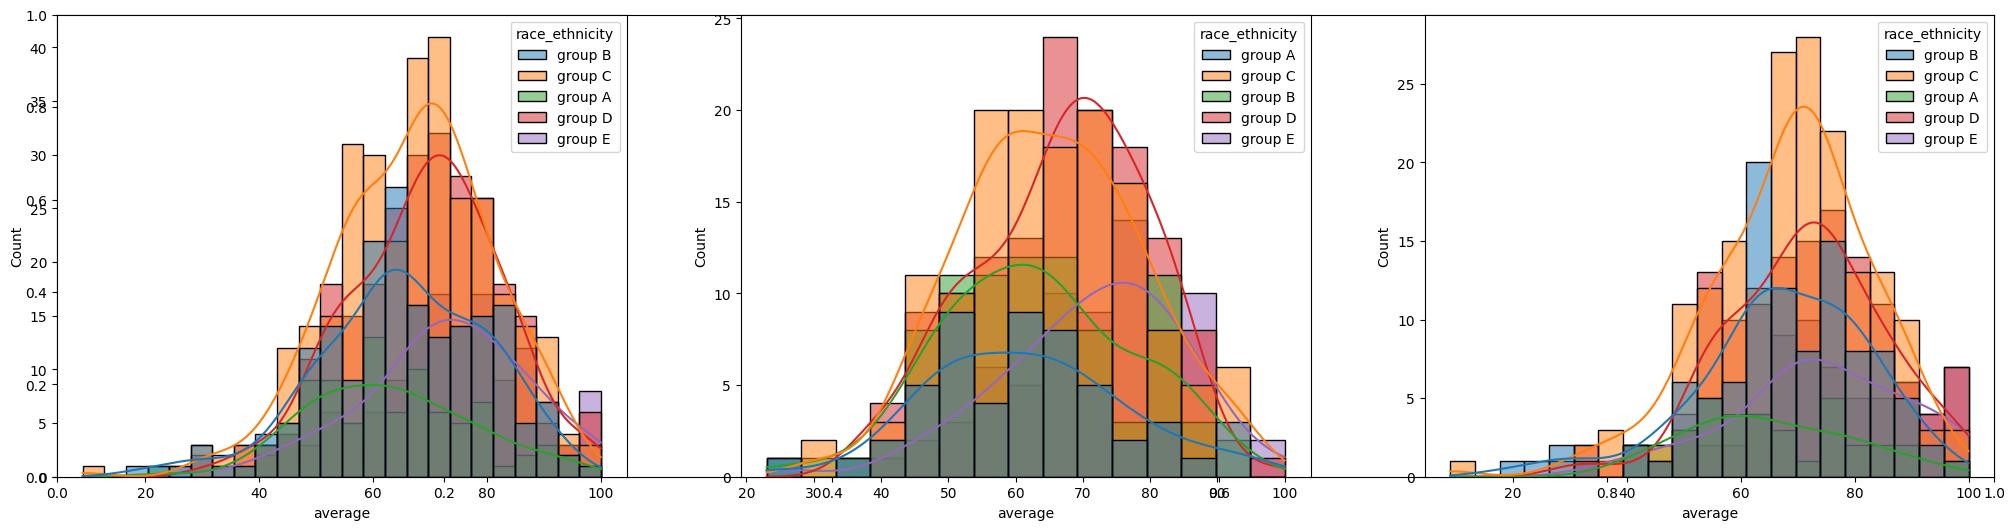

In [ ]:
plt.subplots(figsize=(25,6))
plt.subplot(131) # # 1 row, 3 columns, chart 1
ax = sns.histplot(data=df,x='average',kde=True,hue='race_ethnicity')

plt.subplot(132) # chart 1
ax=sns.histplot(data=df[df.gender=='male'],x='average',kde=True,hue='race_ethnicity')

plt.subplot(133) # chart 3
ax=sns.histplot(data=df[df.gender=='female'],x='average',kde=True,hue='race_ethnicity')
plt.show() 

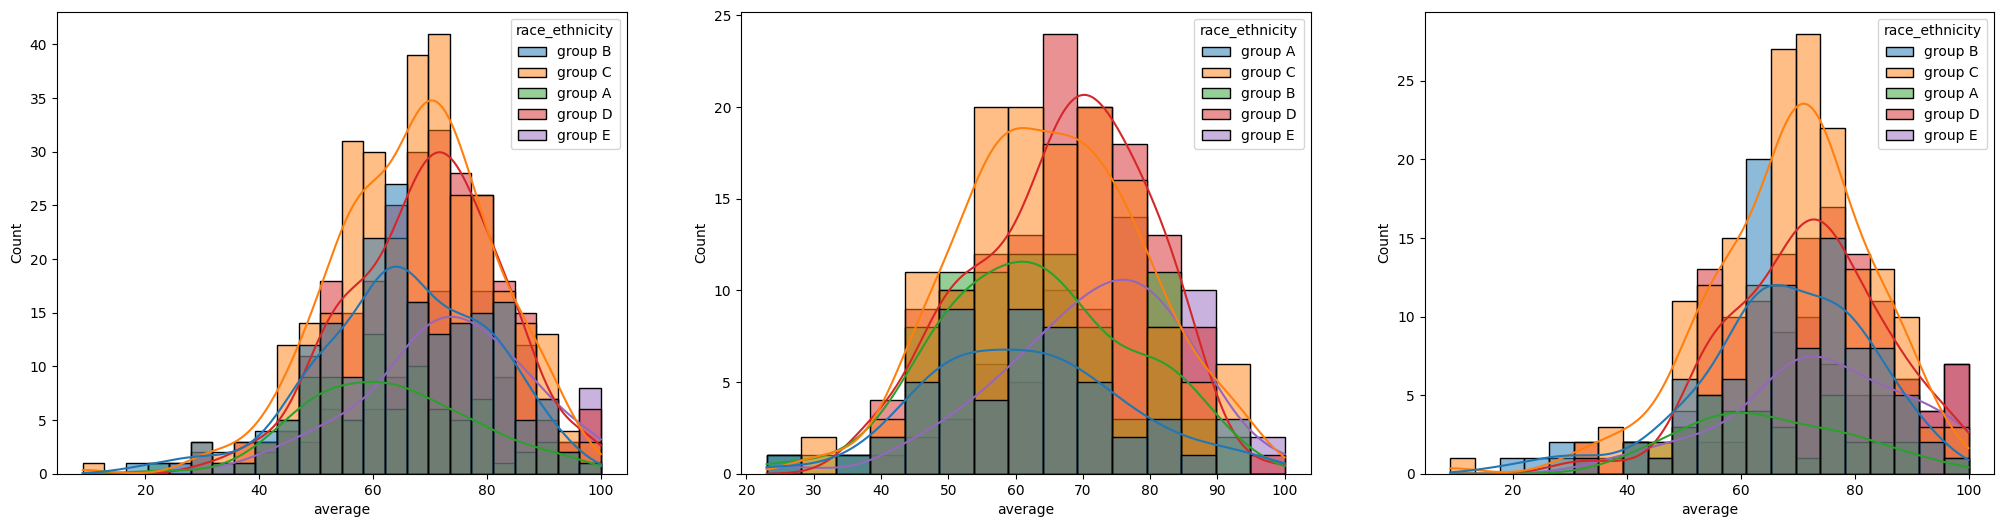

In [56]:
plt.figure(figsize=(25, 6))

plt.subplot(131)
sns.histplot(data=df, x='average', kde=True, hue='race_ethnicity')

plt.subplot(132)
sns.histplot(
    data=df[df.gender == 'male'],
    x='average',
    kde=True,
    hue='race_ethnicity'
)

plt.subplot(133)
sns.histplot(
    data=df[df.gender == 'female'],
    x='average',
    kde=True,
    hue='race_ethnicity'
)

plt.show()

#####  Insights
- Students of group A and group B tends to perform poorly in exam.
- Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female

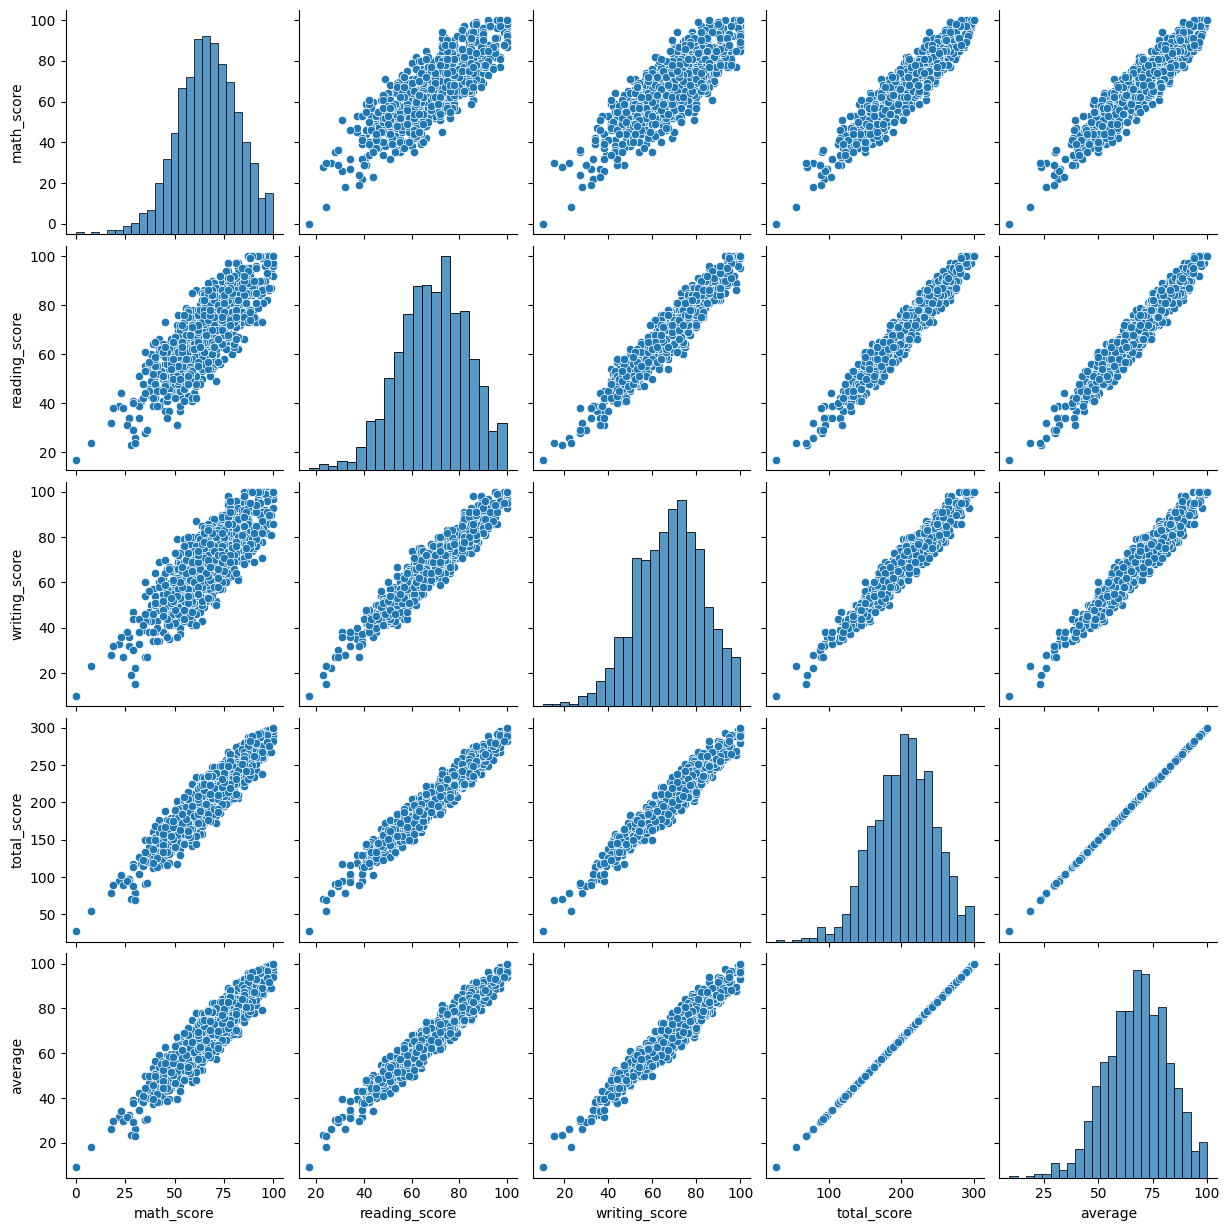

In [ ]:
sns.pairplot(df) # pairplot() is used to visualize the relationship between multiple numerical columns in a dataset.

<Axes: >

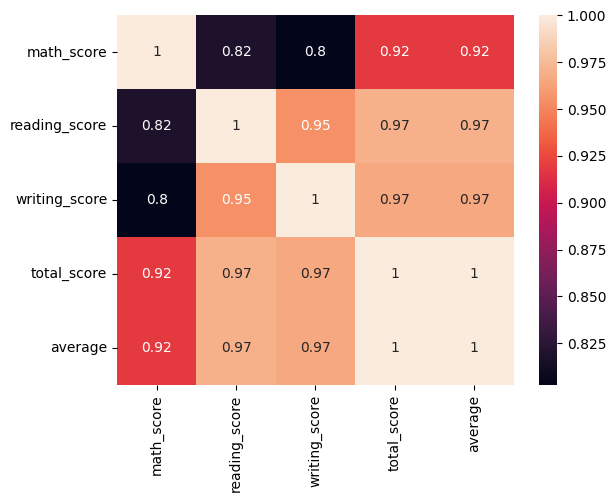

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True) 
# A heatmap is a data visualization technique that represents values using different colors, making it easy to identify patterns,
# relationships, and high or low values.